In [1]:
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import polars as pl
from utils.cleaning import *
from common.helper import *
from utils.plotting import *
import missingno as msno
from IPython.display import display

In [2]:
df = load_brfss()
dfn = load_brfss("with_null_target_v3")

In [3]:
df.describe()

,DIABETES,SEX,INCOME,ARTHRITIS,EMPHYSEMA,DEPRESSION,KIDNEY,HIGHBP,HIGHCHOL,DRINK,...,DIFFWALK,DIFFDRES,DIFFALON,HEART,STROKE,ASTHMA,SMOKER,EXERCISE,VETERAN,CANCER_DIAGNOSIS
count,1.736689e+06,1.736413e+06,1.402577e+06,1.726951e+06,1.728932e+06,1.728175e+06,1.730825e+06,1.730593e+06,1.515243e+06,1.628061e+06,...,1.668735e+06,1.669740e+06,1.663671e+06,1.720022e+06,1.732025e+06,1.723958e+06,1.651675e+06,1.678732e+06,1.728167e+06,1.728612e+06
mean,1.435887e-01,5.425783e-01,2.932089e+00,6.691574e-01,9.190807e-01,8.025449e-01,9.587931e-01,4.031485e-01,3.998448e-01,4.817737e-01,...,8.311775e-01,9.569586e-01,9.227119e-01,9.142976e-01,9.578124e-01,9.706211e-02,2.363691e+00,2.592808e-01,8.760293e-01,1.728115e-01
std,3.506723e-01,4.981839e-01,1.370426e+00,4.705166e-01,2.727112e-01,3.980787e-01,1.987686e-01,4.905303e-01,4.898664e-01,4.996678e-01,...,3.745952e-01,2.029505e-01,2.670481e-01,2.799242e-01,2.010170e-01,2.960424e-01,9.335132e-01,4.382401e-01,3.295482e-01,3.780843e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00
50%,0.000000e+00,1.000000e+00,4.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,3.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00
75%,0.000000e+00,1.000000e+00,4.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,3.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00
max,1.000000e+00,1.000000e+00,4.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,3.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [4]:
dfn.describe()

,DIABETES,SEX,INCOME,ARTHRITIS,EMPHYSEMA,DEPRESSION,KIDNEY,HIGHBP,HIGHCHOL,DRINK,...,DIFFWALK,DIFFDRES,DIFFALON,HEART,STROKE,ASTHMA,SMOKER,EXERCISE,VETERAN,CANCER_DIAGNOSIS
count,1.736689e+06,1.740016e+06,1.404398e+06,1.729505e+06,1.731553e+06,1.730789e+06,1.733409e+06,1.733498e+06,1.517348e+06,1.630917e+06,...,1.671719e+06,1.672746e+06,1.666642e+06,1.722611e+06,1.734737e+06,1.726621e+06,1.654616e+06,1.681911e+06,1.731378e+06,1.731217e+06
mean,1.435887e-01,5.424375e-01,2.931049e+00,6.690984e-01,9.189918e-01,8.024387e-01,9.587639e-01,4.032811e-01,3.999406e-01,4.820276e-01,...,8.309614e-01,9.568452e-01,9.225581e-01,9.142308e-01,9.577665e-01,9.713075e-02,2.363554e+00,2.594668e-01,8.760386e-01,1.727842e-01
std,3.506723e-01,4.981959e-01,1.370948e+00,4.705378e-01,2.728478e-01,3.981595e-01,1.988358e-01,4.905564e-01,4.898860e-01,4.996770e-01,...,3.747861e-01,2.032055e-01,2.672915e-01,2.800230e-01,2.011215e-01,2.961358e-01,9.336738e-01,4.383422e-01,3.295376e-01,3.780607e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00
50%,0.000000e+00,1.000000e+00,4.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,3.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00
75%,0.000000e+00,1.000000e+00,4.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,3.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00
max,1.000000e+00,1.000000e+00,4.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,3.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [5]:
df.DIABETES.value_counts()

DIABETES
0    1487320
1     249369
Name: count, dtype: int64

In [6]:
dfn.DIABETES.value_counts(dropna=False)

DIABETES
0.0    1487320
1.0     249369
NaN       3611
Name: count, dtype: int64

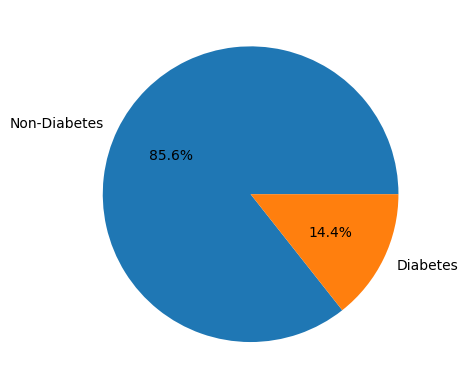

In [7]:
fig, ax = plt.subplots()
ax.pie(x=df.DIABETES.value_counts(), labels=["Non-Diabetes", "Diabetes"], autopct='%1.1f%%')
plt.show()

In [8]:
dfn.DIABETES.value_counts(dropna=False)

DIABETES
0.0    1487320
1.0     249369
NaN       3611
Name: count, dtype: int64

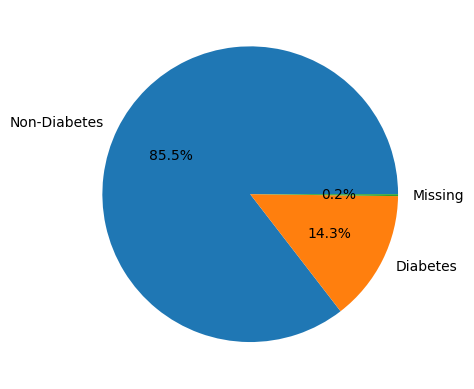

In [9]:
fig, ax = plt.subplots()
ax.pie(x=dfn.DIABETES.value_counts(dropna=False), labels=["Non-Diabetes", "Diabetes", "Missing"], autopct='%1.1f%%', radius=1)
plt.show()

In [10]:
df[["DIABETES", "SEX"]].groupby(by="DIABETES").value_counts(dropna=False)

DIABETES  SEX
0         1.0    805147
          0.0    681936
          NaN       237
1         1.0    136993
          0.0    112337
          NaN        39
Name: count, dtype: int64

In [11]:
# for col in df.columns:

#     if col == 'DIABETES':
#         continue

#     c = df[col].value_counts(dropna=False)
#     p = df[col].value_counts(dropna=False, normalize=True)
    

#     if col == 'DIABETES':
#         r = pd.concat([c, p], axis=1, keys=['counts', '%'])
#         continue

#     diab_c = df[["DIABETES", col]].groupby(by="DIABETES").value_counts(dropna=False)
#     diab_p = df[["DIABETES", col]].groupby(by="DIABETES").value_counts(dropna=False, normalize=True)

#     r = pd.concat([c, p, diab_c[0], diab_p[0], diab_c[1], diab_p[1]], axis=1, keys=['counts', '%', 'dn_counts', 'dn_%', 'dy_counts', 'dy_%'])
#     r.to_csv(f"feature_tables/{col}.scratch.csv")
#     print(r)
#     print()

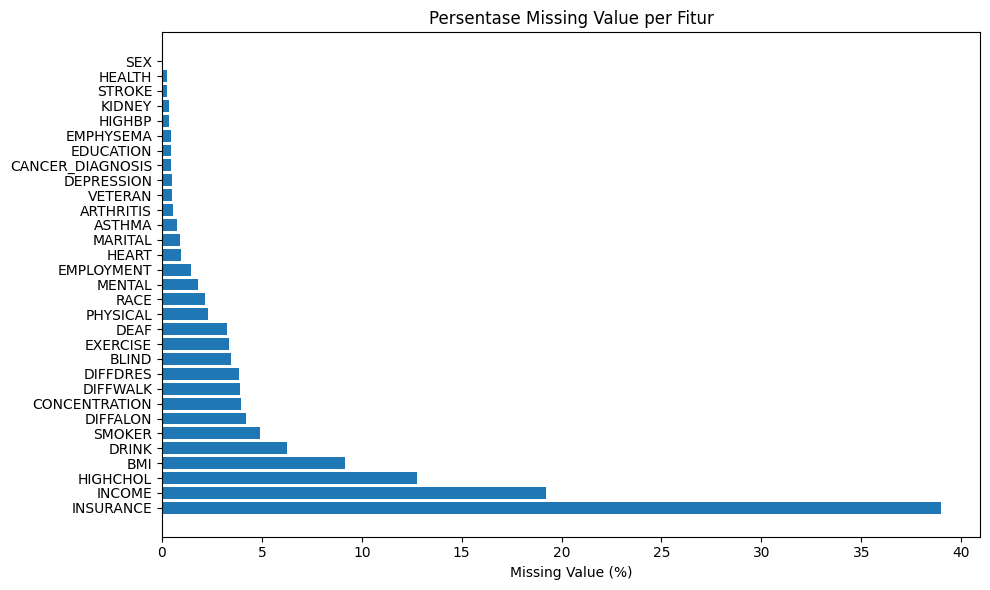

In [12]:
# Calculate missing percentage per feature
missing_pct = (df.isna().sum() / len(df) * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]  # only features with missing

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(missing_pct.index, missing_pct.values)
ax.set_xlabel('Missing Value (%)')
ax.set_title('Persentase Missing Value per Fitur')
plt.tight_layout()
plt.show()

<Axes: >

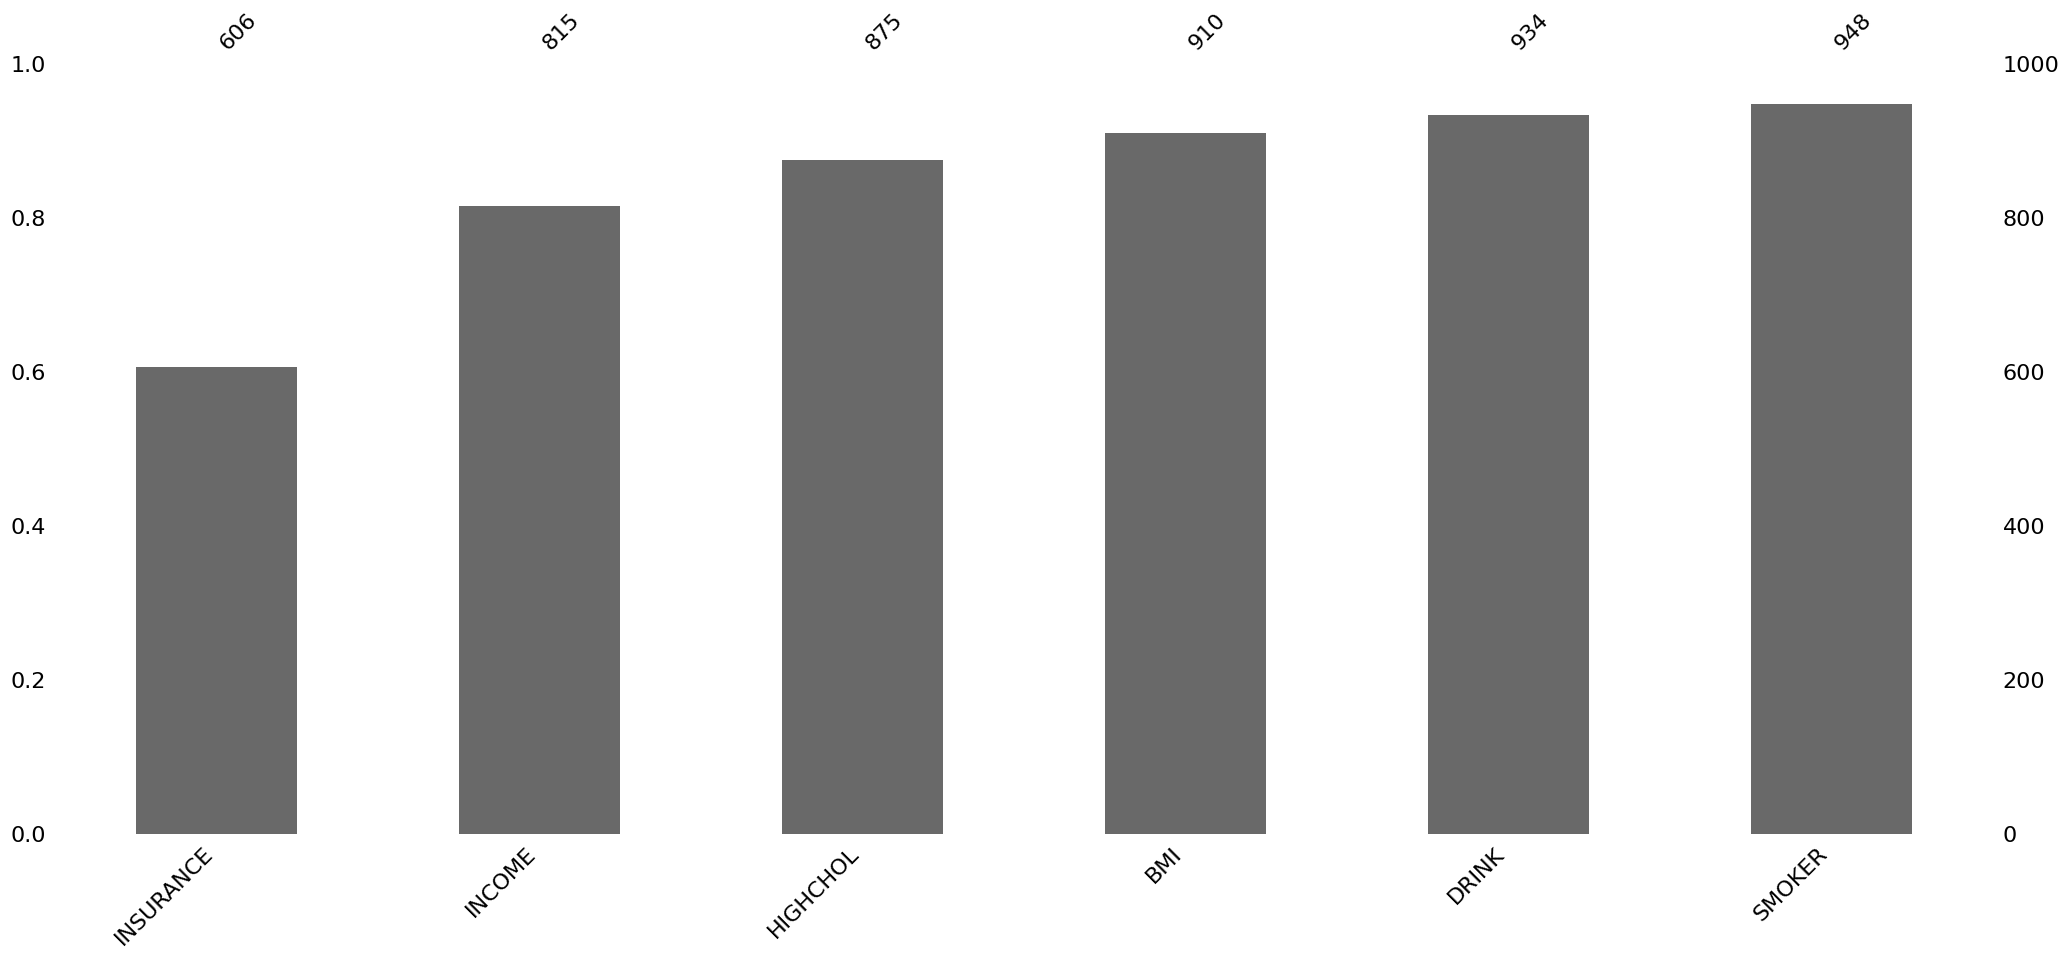

In [24]:
msno.bar(df[["INSURANCE", "INCOME", "HIGHCHOL", "BMI", "DRINK", "SMOKER"]].sample(1000), sort="ascending")

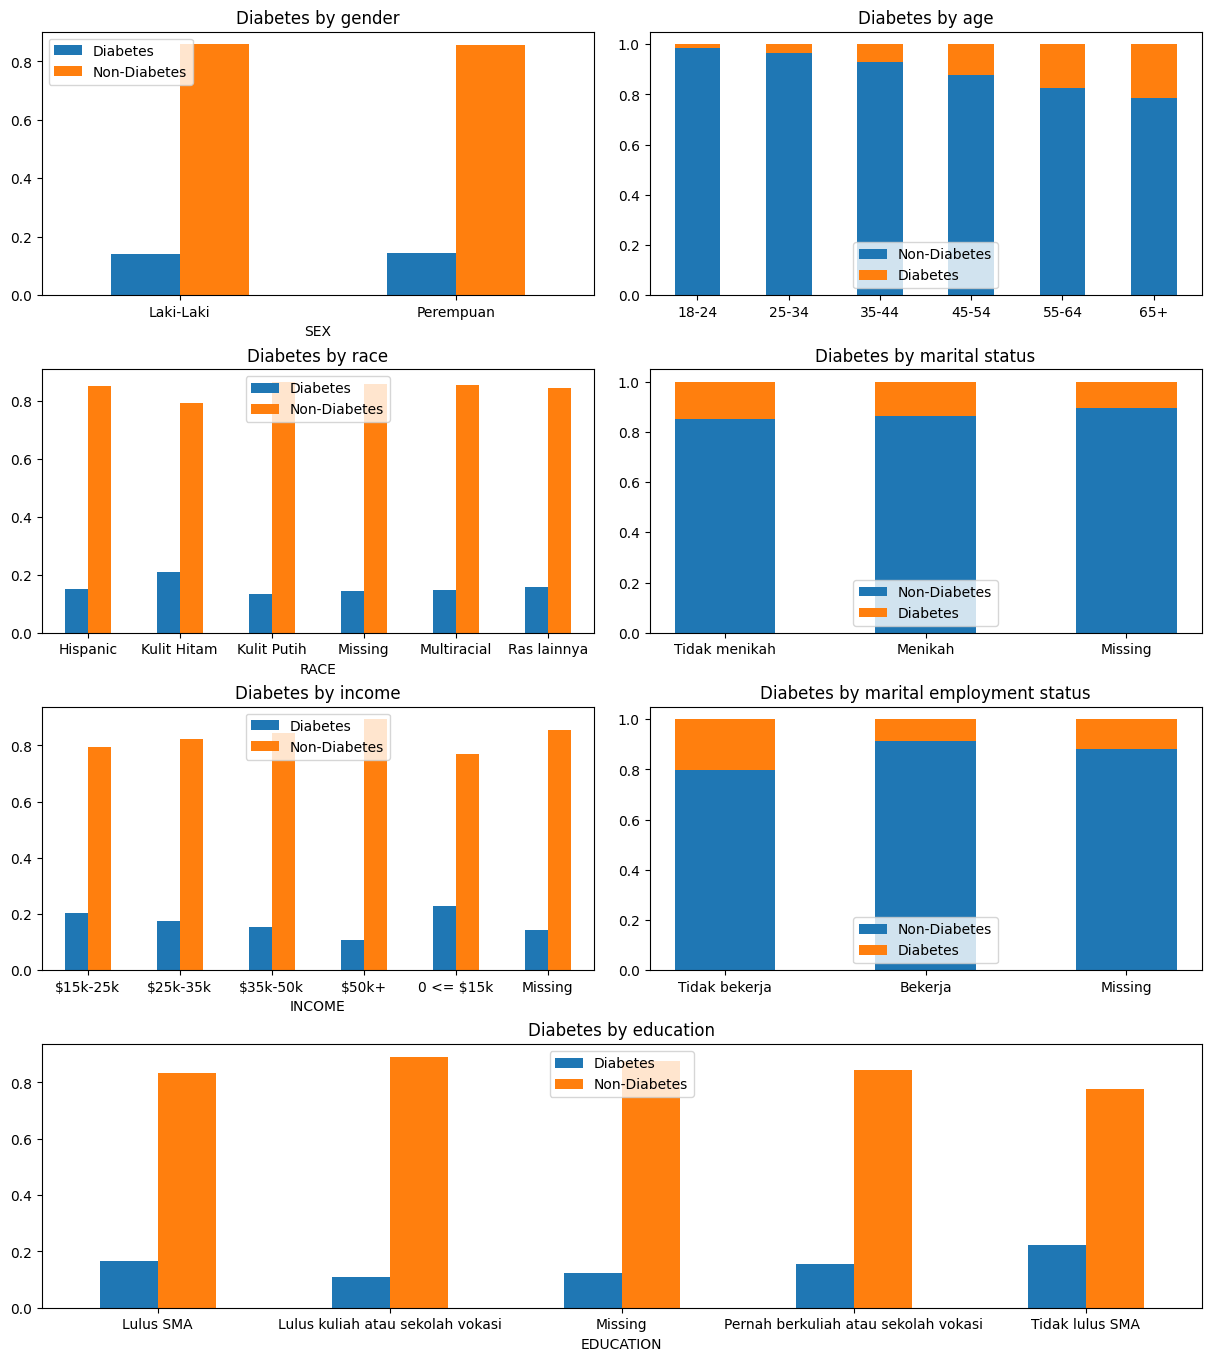

In [27]:
# Demographic and Socioeconomic characteristics
# fig, axs = plt.subplots(nrows=4, 
#                         ncols=2, 
#                         sharex=False, 
#                         sharey=False,
#                         layout="constrained",
#                         figsize=(12.0, 13.5)
#                     )

fig = plt.figure(layout="constrained", figsize=(12.0, 13.5))
gs = plt.GridSpec(nrows=4, ncols=2, figure=fig)
axs = []

for i in range(gs.nrows):
    if i == gs.nrows - 1:
        axs.append(fig.add_subplot(gs[i, :]))
        continue

    for j in range(gs.ncols):
        axs.append(fig.add_subplot(gs[i, j]))

generate_grouped_bar_plot(df, "SEX", labels={
    0: "Laki-Laki",
    1: "Perempuan",
},
    percentage=True,
    ax=axs[0],
    dropna=True,
    title="Diabetes by gender")


generate_stacked_bar_plot(df, "AGE", labels={
    0: "18-24",
    1: "25-34",
    2: "35-44",
    3: "45-54",
    4: "55-64",
    5: "65+",
},
    legend_loc="lower center",
    ax=axs[1],
    dropna=False,
    title="Diabetes by age"
)

generate_grouped_bar_plot(df, "RACE", labels={
    0: "Kulit Putih",
    1: "Kulit Hitam",
    2: "Ras lainnya",
    3: "Multiracial",
    4: "Hispanic",
},
    legend_loc="upper center",
    ax=axs[2],
    dropna=False,
    title="Diabetes by race"
)

generate_stacked_bar_plot(df, "MARITAL", labels={
    1: "Menikah",
    0: "Tidak menikah",
},
    percentage=True,
    ax=axs[3],
    dropna=False,
    title="Diabetes by marital status",
    legend_loc="lower center"
    )


generate_grouped_bar_plot(df, "INCOME", labels={
    0: "0 <= $15k",
    1: "$15k-25k",
    2: "$25k-35k",
    3: "$35k-50k",
    4: "$50k+",
},
    legend_loc="upper center",
    ax=axs[4],
    dropna=False,
    title="Diabetes by income"
)

generate_stacked_bar_plot(df, "EMPLOYMENT", labels={
    0: "Tidak bekerja",
    1: "Bekerja",
},
    percentage=True,
    ax=axs[5],
    dropna=False,
    title="Diabetes by marital employment status",
    legend_loc="lower center"
    )

generate_grouped_bar_plot(df, "EDUCATION", labels={
    0: "Tidak lulus SMA",
    1: "Lulus SMA",
    2: "Pernah berkuliah atau sekolah vokasi",
    3: "Lulus kuliah atau sekolah vokasi",
},
    legend_loc="upper center",
    ax=axs[6],
    dropna=False,
    title="Diabetes by education"
)


# axs[3, 1].set_axis_off()

plt.show()

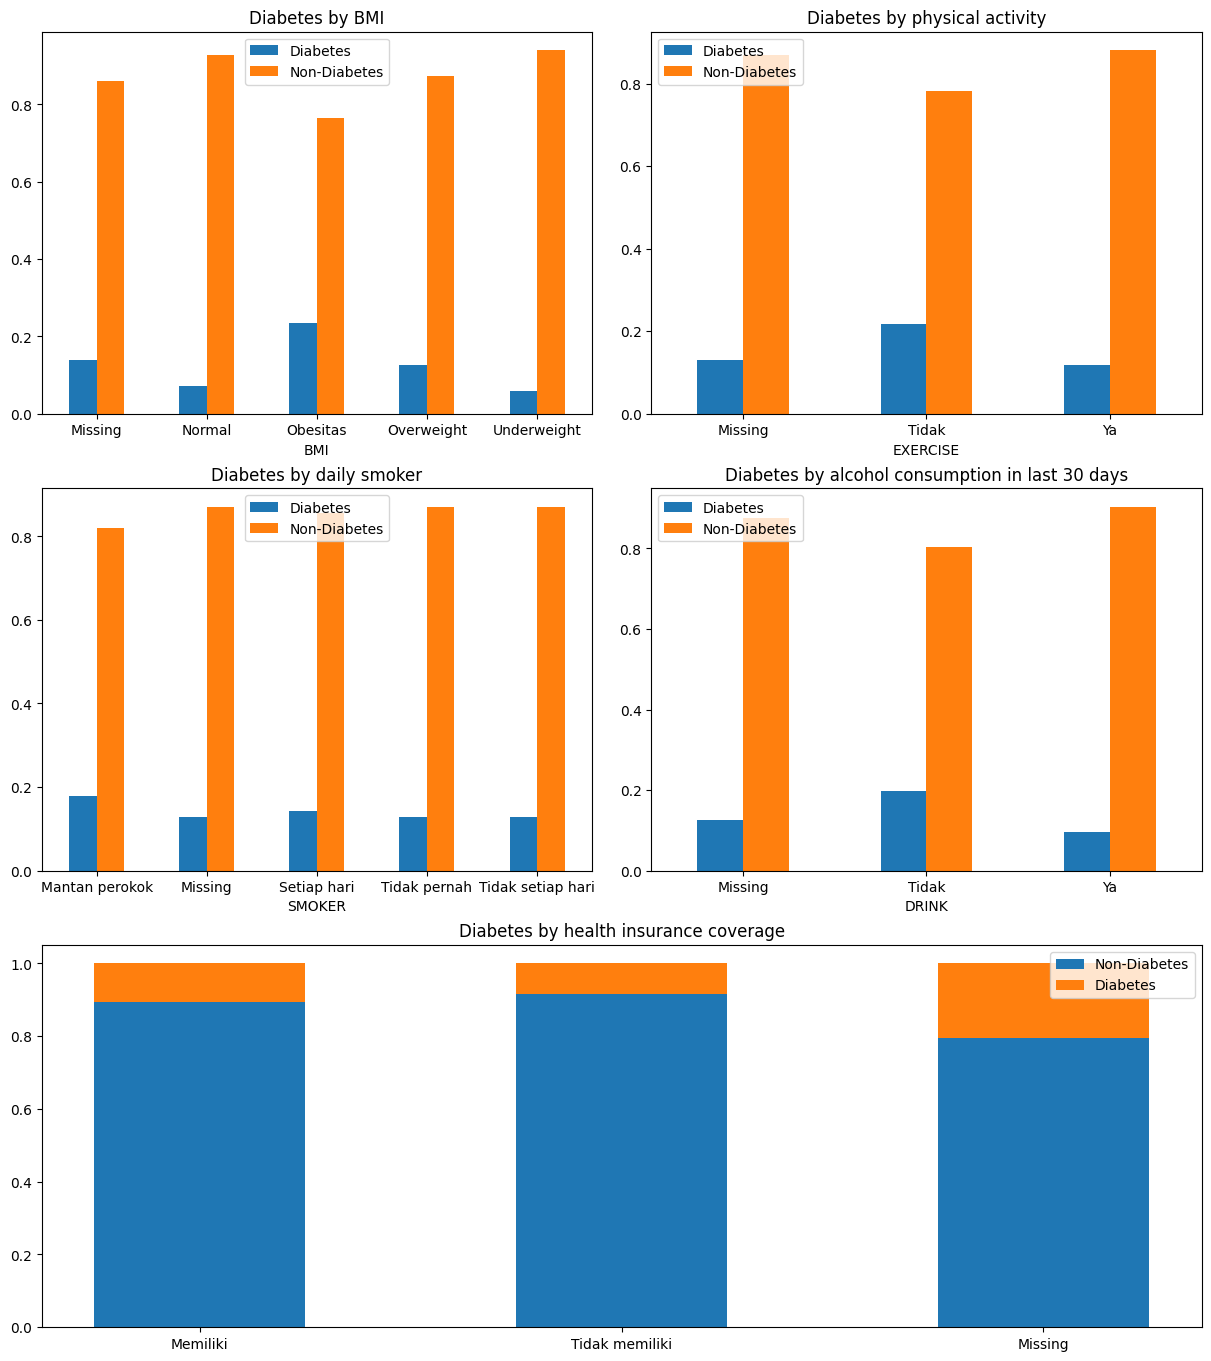

In [28]:
# Behavioral, physical, and function characteristics
# fig, axs = plt.subplots(nrows=3, 
#                         ncols=2, 
#                         sharex=False, 
#                         sharey=False,
#                         layout="constrained",
#                         figsize=(12.0, 13.5)
#                     )

fig = plt.figure(layout="constrained", figsize=(12.0, 13.5))
gs = plt.GridSpec(nrows=3, ncols=2, figure=fig)
axs = []

for i in range(gs.nrows):
    if i == gs.nrows - 1:
        axs.append(fig.add_subplot(gs[i, :]))
        continue

    for j in range(gs.ncols):
        axs.append(fig.add_subplot(gs[i, j]))

generate_grouped_bar_plot(df, "BMI", labels={
    0: "Underweight",
    1: "Normal",
    2: "Overweight",
    3: "Obesitas",
},
    percentage=True,
    ax=axs[0],
    dropna=False,
    title="Diabetes by BMI",
    legend_loc="upper center")

generate_grouped_bar_plot(df, "EXERCISE", labels={
    0: "Ya",
    1: "Tidak",
},
    percentage=True,
    ax=axs[1],
    dropna=False,
    title="Diabetes by physical activity")

generate_grouped_bar_plot(df, "SMOKER", labels={
    0: "Setiap hari",
    1: "Tidak setiap hari",
    2: "Mantan perokok",
    3: "Tidak pernah",
},
    legend_loc="upper center",
    ax=axs[2],
    dropna=False,
    title="Diabetes by daily smoker"
)

generate_grouped_bar_plot(df, "DRINK", labels={
    0: "Ya",
    1: "Tidak",
},
    percentage=True,
    ax=axs[3],
    dropna=False,
    title="Diabetes by alcohol consumption in last 30 days")

generate_stacked_bar_plot(df, "INSURANCE", labels={
    0: "Memiliki",
    1: "Tidak memiliki",
},
    percentage=True,
    ax=axs[4],
    dropna=False,
    title="Diabetes by health insurance coverage",
    legend_loc="upper right"
    )

# axs[2].set_axis_off()

plt.show()

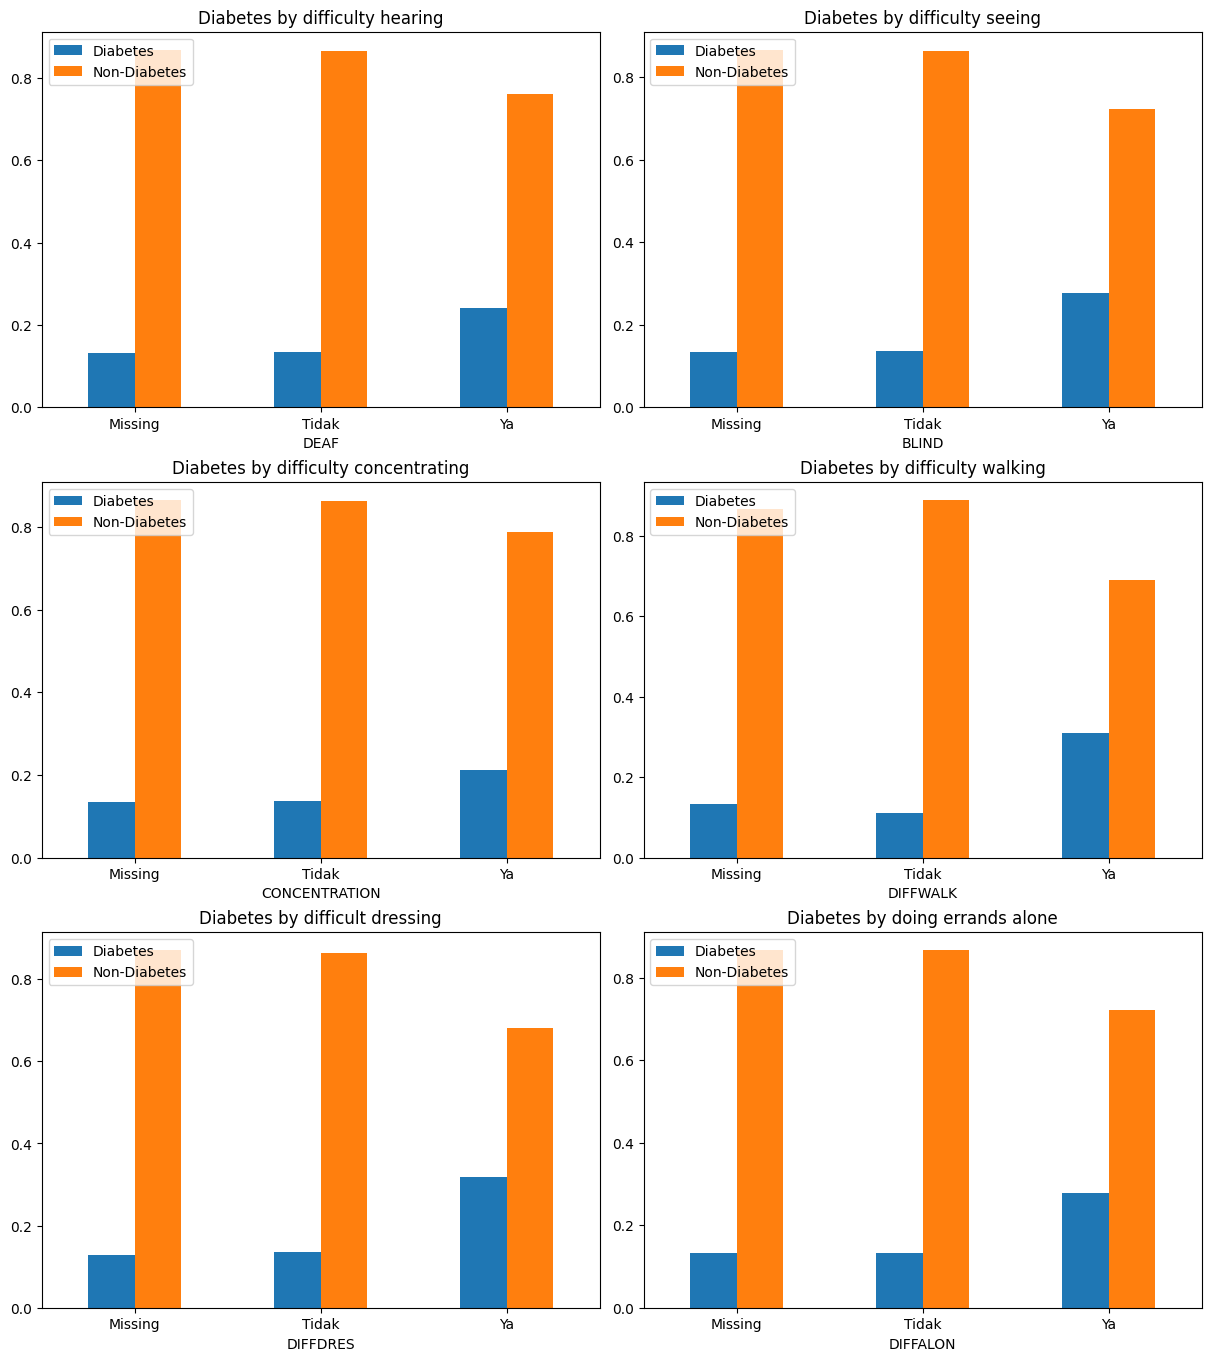

In [16]:
# Disability
fig, axs = plt.subplots(nrows=3, 
                        ncols=2, 
                        sharex=False, 
                        sharey=False,
                        layout="constrained",
                        figsize=(12.0, 13.5)
                    )

generate_grouped_bar_plot(df, "DEAF", labels={
    0: "Ya",
    1: "Tidak",
},
    percentage=True,
    ax=axs[0, 0],
    dropna=False,
    title="Diabetes by difficulty hearing")

generate_grouped_bar_plot(df, "BLIND", labels={
    0: "Ya",
    1: "Tidak",
},
    percentage=True,
    ax=axs[0, 1],
    dropna=False,
    title="Diabetes by difficulty seeing")

generate_grouped_bar_plot(df, "CONCENTRATION", labels={
    0: "Ya",
    1: "Tidak",
},
    percentage=True,
    ax=axs[1, 0],
    dropna=False,
    title="Diabetes by difficulty concentrating")

generate_grouped_bar_plot(df, "DIFFWALK", labels={
    0: "Ya",
    1: "Tidak",
},
    percentage=True,
    ax=axs[1, 1],
    dropna=False,
    title="Diabetes by difficulty walking")

generate_grouped_bar_plot(df, "DIFFDRES", labels={
    0: "Ya",
    1: "Tidak",
},
    percentage=True,
    ax=axs[2, 0],
    dropna=False,
    title="Diabetes by difficult dressing")

generate_grouped_bar_plot(df, "DIFFALON", labels={
    0: "Ya",
    1: "Tidak",
},
    percentage=True,
    ax=axs[2, 1],
    dropna=False,
    title="Diabetes by doing errands alone")

plt.show()

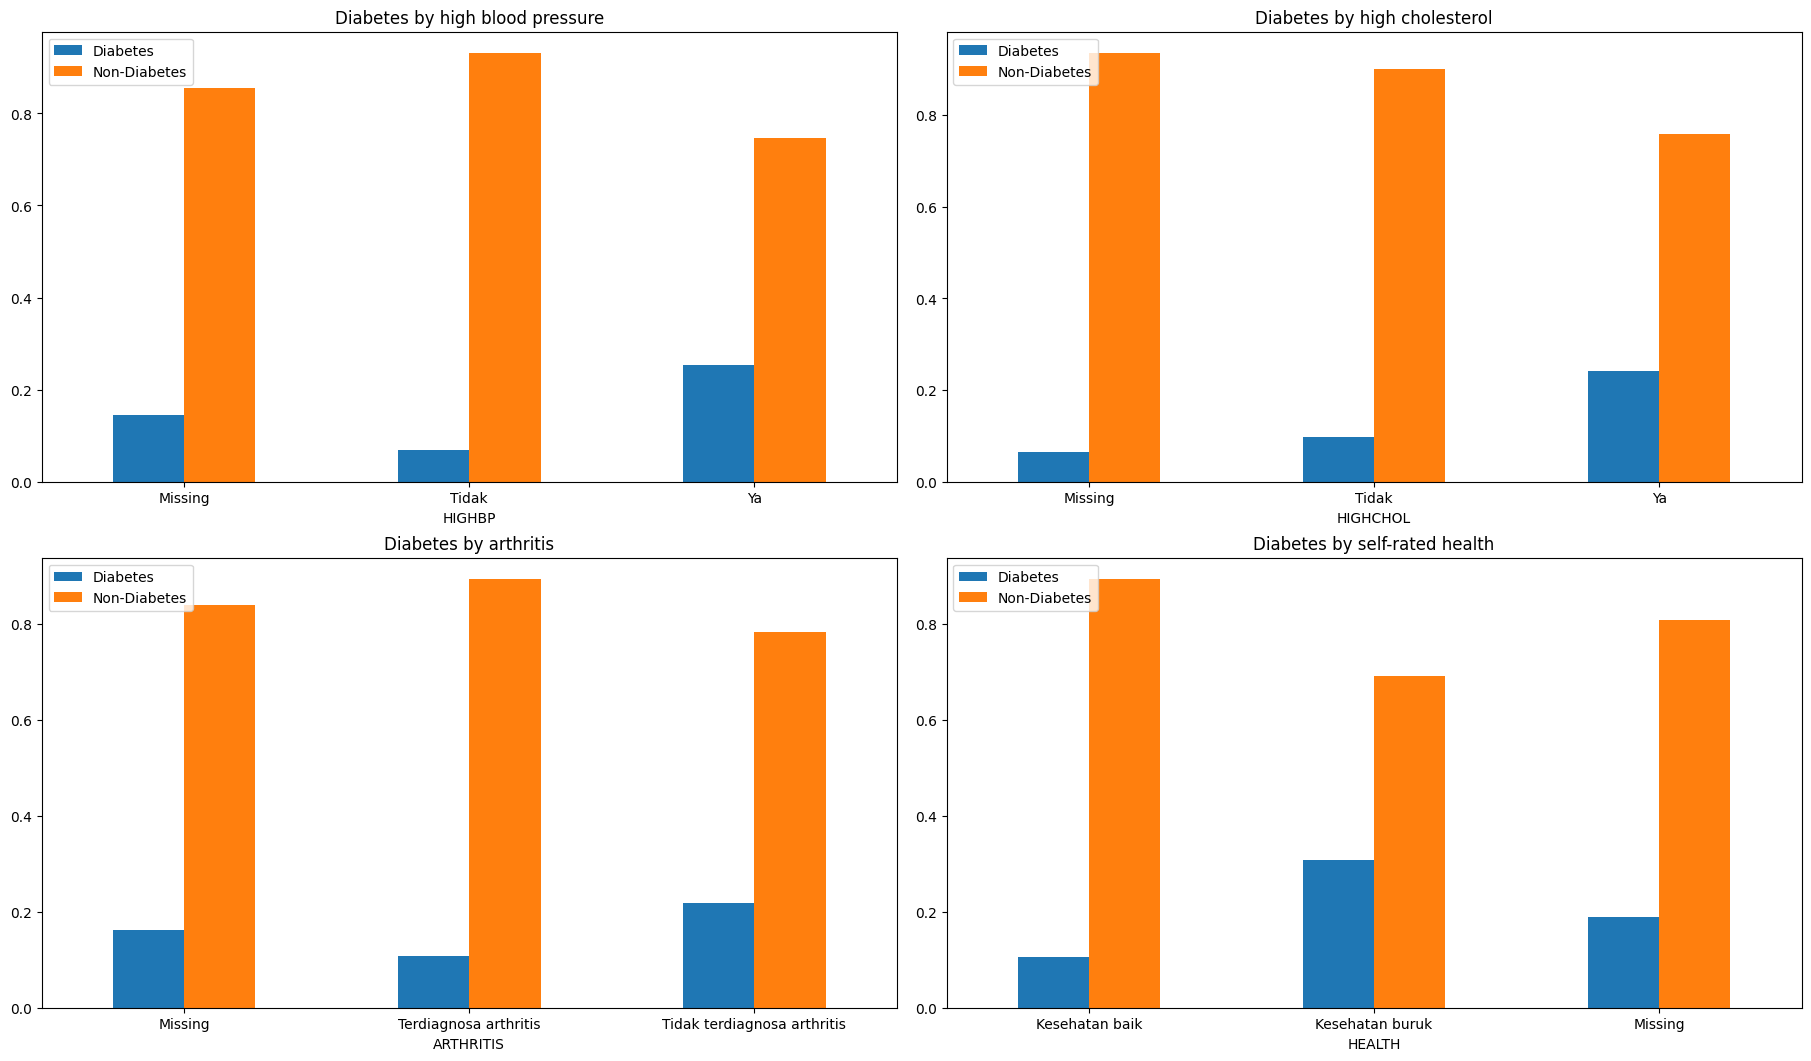

In [17]:
# Health conditions and health status

fig, axs = plt.subplots(nrows=2, 
                        ncols=2, 
                        sharex=False, 
                        sharey=False,
                        layout="constrained",
                        figsize=(18.0, 10.5)
                    )

generate_grouped_bar_plot(df, "HIGHBP", labels={
    1: "Ya",
    0: "Tidak",
},
    percentage=True,
    ax=axs[0, 0],
    dropna=False,
    title="Diabetes by high blood pressure")

generate_grouped_bar_plot(df, "HIGHCHOL", labels={
    1: "Ya",
    0: "Tidak",
},
    percentage=True,
    ax=axs[0, 1],
    dropna=False,
    title="Diabetes by high cholesterol")

generate_grouped_bar_plot(df, "ARTHRITIS", labels={
    1: "Terdiagnosa arthritis",
    0: "Tidak terdiagnosa arthritis",
},
    percentage=True,
    ax=axs[1, 0],
    dropna=False,
    title="Diabetes by arthritis")

generate_grouped_bar_plot(df, "HEALTH", labels={
    1: "Kesehatan buruk",
    0: "Kesehatan baik",
},
    percentage=True,
    ax=axs[1, 1],
    dropna=False,
    title="Diabetes by self-rated health")